<a href="https://colab.research.google.com/github/o-kauan/1CCA_GS_2-Semestre/blob/main/modelagem_linear_global_solution_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
# AVALIAÇÃO: CitizenTech - Análise Estatística e Ciência de Dados Aplicada

###**Integrantes do grupo:**
- Thiago Soalheiro Diamantino // RM: 569316
- Kauan Damasceno de Lima // RM: 573727

In [26]:
# Tema: Clima, Sustentabilidad e Agricultura Familiar (São Paulo) - Bridge AI

###**Justificativa da Escolha da Base de Dados (Contexto CitizenTech):**
Para fundamentar o módulo de inteligência preventiva do assistente digital que propomos como solução para o projeto voltado à população rural e urbana, optou-se por utilizar dados meteorológicos diários históricos extraídos da plataforma Open-Meteo, cobrindo o contexto climático do interior e do ambiente de cidade do estado de São Paulo. A escolha justifica-se pela alta vulnerabilidade demográfica e econômica do campo frente às intempéries climáticas, visto que o envelhecimento da população rural brasileira exige soluções tecnológicas capazes de mitigar riscos associados à agricultura familiar e à mobilidade comunitária.

A base de dados permite correlacionar variáveis quantitativas contínuas (temperatura máxima, umidade relativa do ar e volume de precipitação) com eventos de risco binários (como ocorrência de chuvas fortes). Dessa forma, os modelos estatísticos desenvolvidos (regressões lineares e logísticas) transformam dados brutos em inteligência acionável, permitindo que o assistente calcule previsões precisas e emita alertas antecipados tanto para os moradores locais quanto para os familiares que os auxiliam à distância, reforçando o elo geracional e a segurança no cotidiano rural.

In [27]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
url = 'https://raw.githubusercontent.com/o-kauan/1CCA_GS_2-Semestre/refs/heads/main/Modelagem%20Linear/Base%20de%20dados%20Rural/open-meteo-22.74S47.67W526m.csv'
df = pd.read_csv(url, skiprows=3)
print(df.head())

               time  temperature_2m (°C)  relative_humidity_2m (%)  \
0  2026-11-06T00:00                 21.3                        86   
1  2026-11-06T01:00                 20.9                        88   
2  2026-11-06T02:00                 20.8                        89   
3  2026-11-06T03:00                 20.7                        90   
4  2026-11-06T04:00                 20.7                        91   

   precipitation (mm)  rain (mm)  
0                 0.0        0.0  
1                 0.0        0.0  
2                 0.0        0.0  
3                 0.0        0.0  
4                 0.1        0.1  


### **Exercício 2 - Análise com Distribuição Normal de Probabilidade**

a) A probabilidade desta variável ser menor do que a média dos registros da variável. Na
sequência classifique o evento quanto ao resultado probabilístico.

b) A probabilidade desta variável ser maior que a mediana dos registros da variável. Na
sequência classifique o evento quanto ao resultado probabilístico.


In [29]:
media_temp = df['temperature_2m (°C)'].mean()
print("Média da temperatura:", media_temp)

mediana_temp = df['temperature_2m (°C)'].median()
print("Mediana da temperatura:", mediana_temp)

sigma = df['temperature_2m (°C)'].std() # desvio padrão
print("Desvio padrão (sigma):", sigma)

# a) A probabilidade desta variável ser menor do que a média dos registros da variável
prob_menor_media = stats.norm.cdf(media_temp, loc=media_temp, scale=sigma)
print("\nProbabilidade de ser menor que a média:", prob_menor_media)
print(f"a) P(x < Média) = {prob_menor_media:.4f} ({prob_menor_media * 100:.1f}%) -> Evento Equiprovável(ou evento certo/50-50).")

# b) A probabilidade desta variável ser maior que a mediana dos registros da variável
prob_maior_mediana = 1 - stats.norm.cdf(mediana_temp, loc=media_temp, scale=sigma)
print(f"\nProbabilidade de ser maior que a mediana: {prob_maior_mediana:.4f}")
print(f"b) P(x > Mediana) = {prob_maior_mediana:.4f} ({prob_maior_mediana * 100:.1f}%) -> Evento Equiprovável(ou de probabilidade intermediária/50%).")

Média da temperatura: 21.463690476190475
Mediana da temperatura: 20.95
Desvio padrão (sigma): 3.7998491239388925

Probabilidade de ser menor que a média: 0.5
a) P(x < Média) = 0.5000 (50.0%) -> Evento Equiprovável(ou evento certo/50-50).

Probabilidade de ser maior que a mediana: 0.5538
b) P(x > Mediana) = 0.5538 (55.4%) -> Evento Equiprovável(ou de probabilidade intermediária/50%).


### **Exercício 3**

a) A média amostral é menor do que a média populacional de referência, a um nível de
significância de 6%, amostra de tamanho 20 e desvio padrão de referência igual ao desvio
padrão populacional dos dados.

b) A média amostral é maior do que a média populacional de referência, a um nível de
significância de 9%, amostra de tamanho 25 e desvio padrão de referência igual ao desvio
padrão populacional dos dados.


In [30]:
amostra_20 = df['temperature_2m (°C)'].sample(n=20, random_state=42)
amostra_25 = df['temperature_2m (°C)'].sample(n=25, random_state=42)

media_amostra_20 = amostra_20.mean()
media_amostra_25 = amostra_25.mean()

desvio_padrao_amostra_20 = amostra_20.std()
desvio_padrao_amostra_25 = amostra_25.std()

# a) Média amostral menor do que a média populacional de referência (alfa = 6%, n = 20)
z_stat_20 = (media_amostra_20 - media_temp) / (sigma / np.sqrt(20)) # Calcula quantos desvios padrão a média da amostra está distante da média populacional de referência (media_temp).
p_value_20 = stats.norm.cdf(z_stat_20) # Utiliza a função acumulada da distribuição normal (stats.norm.cdf) para calcular a probabilidade de obtermos uma média amostral tão baixa (ou ainda mais baixa) do que a que encontramos
print(f"a) Média Amostral (n=20): {media_amostra_20:.4f}")
print(f"Teste Hipotetico: Z = {z_stat_20:.4f}, p-valor: {p_value_20:.4f}")
if p_value_20 < 0.06:
  print("-> Rejeita-se a hipótese nula (H0) ao nível de significância de 6%. A média amostral é menor do que a média populacional de referência.")
else:
  print("-> Não rejeita-se a hipótese nula (H0). A média amostral não é menor do que a média populacional de referência.")

# b) Média amostral maior do que a média populacional de referência (alfa = 9%, n = 25)
z_stat_25 = (media_amostra_25 - media_temp) / (sigma / np.sqrt(25))
p_value_25 = 1 - stats.norm.cdf(z_stat_25)
print(f"\nb) Média Amostral (n=25): {media_amostra_25:.4f}")
print(f"Teste Hipotetico: Z = {z_stat_25:.4f}, p-valor: {p_value_25:.4f}")
if p_value_25 < 0.09:
  print("-> Rejeita-se a hipótese nula (H0) ao nível de significância de 9%.")
else:
    print("-> Não se rejeita a hipótese nula (H0) ao nível de significância de 9%.")

a) Média Amostral (n=20): 21.9600
Teste Hipotetico: Z = 0.5841, p-valor: 0.7204
-> Não rejeita-se a hipótese nula (H0). A média amostral não é menor do que a média populacional de referência.

b) Média Amostral (n=25): 23.0200
Teste Hipotetico: Z = 2.0479, p-valor: 0.0203
-> Rejeita-se a hipótese nula (H0) ao nível de significância de 9%.


### **Exercício 4 - Análise Bivariada entre 02 variáveis quantitativas**

a) O Gráfico de Dispersão, com título e nomes nos eixos x e y, e interprete o resultado.

b) A Covariância e a Correlação Linear de Pearson, e interprete os resultados.

c) O Gráfico de Correlação Linear de Pearson, e interprete o resultado.

d) A reta da Regressão Linear Simples (no Gráfico de Dispersão), e a Equação da
Regressão Linear Simples.

e) A verificação da adequação do modelo (R² e Teste F), e interprete os resultados.

f) Faça uma previsão.

### **a) Gráfico de Dispersão**

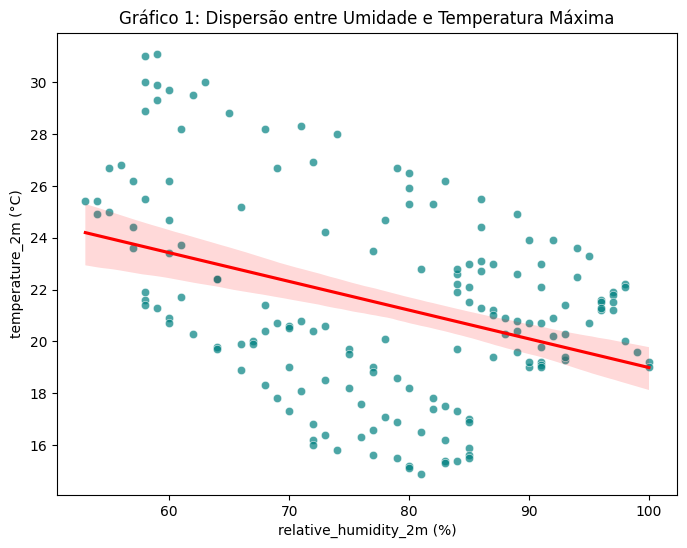

In [31]:
anal_x = df['relative_humidity_2m (%)']
anal_y = df['temperature_2m (°C)']

plt.figure(figsize=(8, 6))
sns.scatterplot(x=anal_x, y=anal_y, alpha=0.7, color='teal')
plt.title('Gráfico 1: Dispersão entre Umidade e Temperatura Máxima')
plt.xlabel('Umidade (%)')
plt.ylabel('Temperatura Máxima (°C)')
sns.regplot(x=anal_x, y=anal_y, scatter=False, color='red')
plt.savefig('grafico_bivariado.png', dpi=300, bbox_inches='tight')
plt.show()

#### **Interpretação (Item a):**
O **Gráfico de Dispersão** mostra uma tendência linear decrescente entre a umidade e a temperatura. À medida que a umidade relativa do ar aumenta, a temperatura máxima tende a diminuir, sugerindo uma associação negativa entre elas.

### **b) A Covariância e a Correlação Linear de Pearson**

In [32]:
import numpy as np

covariancia = np.cov(anal_x, anal_y)[0, 1]
correlacao_pearson = covariancia / (anal_x.std() * anal_y.std())
print(f"Covariância: {covariancia:.4f}")
print(f"Correlação de Pearson: {correlacao_pearson:.4f}")

Covariância: -18.2018
Correlação de Pearson: -0.3737


#### **Interpretação (Item b):**
* **Covariância (-18.2018):** O sinal negativo confirma que as variáveis variam em direções opostas (relação inversa).
* **Correlação de Pearson (-0.3737):** Indica uma correlação linear negativa de intensidade **moderada** (coeficiente entre -0.30 e -0.50).

### **c) Gráfico de Correlação (Heatmap da Matriz de Correlação)**

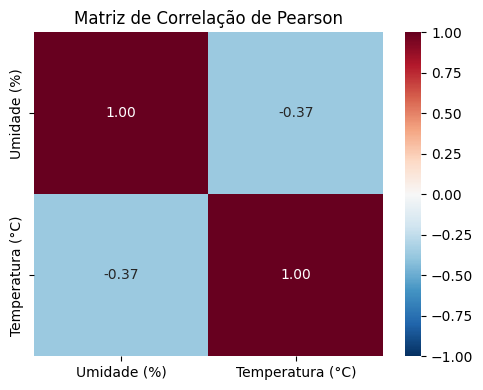

In [33]:
plt.figure(figsize=(5, 4))
corr_bivariada = df[['relative_humidity_2m (%)', 'temperature_2m (°C)']].corr()
corr_bivariada_renomeada = corr_bivariada.rename(
    columns={'relative_humidity_2m (%)': 'Umidade (%)', 'temperature_2m (°C)': 'Temperatura (°C)'},
    index={'relative_humidity_2m (%)': 'Umidade (%)', 'temperature_2m (°C)': 'Temperatura (°C)'}
)
sns.heatmap(corr_bivariada_renomeada, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Matriz de Correlação de Pearson')
plt.tight_layout()
plt.show()

#### **Interpretação (Item c):**
O Heatmap visualiza a força da relação linear. O tom azul claro na interseção entre Umidade e Temperatura indica numericamente a correlação moderada e negativa de **-0.37**, reforçando a tendência de temperaturas baixas em cenários de alta umidade, uma aumentando acaba diminuindo a outra.

### **d) Reta da regressão e equação**

Equação: Temperatura = 30.0641 + (-0.1108) · Umidade



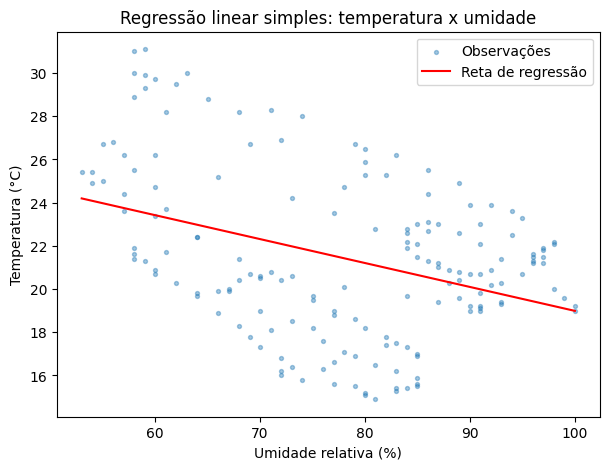

In [34]:
reg = stats.linregress(anal_x, anal_y)
b0, b1 = reg.intercept, reg.slope
print(f'Equação: Temperatura = {b0:.4f} + ({b1:.4f}) · Umidade')
print("")

plt.figure(figsize=(7, 5))
plt.scatter(anal_x, anal_y, s=8, alpha=0.4, label='Observações')
xs = np.linspace(anal_x.min(), anal_x.max(), 100)
plt.plot(xs, b0 + b1 * xs, color='red', label='Reta de regressão')
plt.title('Regressão linear simples: temperatura x umidade')
plt.xlabel('Umidade relativa (%)')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.show()

### **e) Adequação do modelo: R² e Teste F**

In [35]:
X_sm = sm.add_constant(anal_x)
modelo_bivariado = sm.OLS(anal_y, X_sm).fit()

r2_biv = modelo_bivariado.rsquared
f_calc_biv = modelo_bivariado.fvalue
p_val_f_biv = modelo_bivariado.f_pvalue

print(f"Coeficiente de Determinação (R²): {r2_biv:.4f} ({r2_biv * 100:.2f}% da variação da temperatura é explicada pela umidade)")
print(f"Estatística F: {f_calc_biv:.4f}")
print(f"p-valor do Teste F: {p_val_f_biv:.4e}")

Coeficiente de Determinação (R²): 0.1396 (13.96% da variação da temperatura é explicada pela umidade)
Estatística F: 26.9371
p-valor do Teste F: 6.0748e-07


#### **Interpretação (Item e):**
* **R² (0.1396):** O modelo bivariado explica **13.96%** da variação da temperatura a partir da umidade do ar.
* **Teste F (p-valor = 6.07e-07):** Como o p-valor é extremamente próximo de zero (menor que o nível de significância de 5%), **o modelo é globalmente significativo** e a umidade é uma preditora estatisticamente relevante para estimar a temperatura.

### **f) Previsão (troque o valor da umidade se quiser)**

In [36]:
umidade_nova = 25
temp_prevista = b0 + b1 * umidade_nova
print(f'Previsão: com umidade de {umidade_nova}%, temperatura prevista = {temp_prevista:.2f} °C')

Previsão: com umidade de 25%, temperatura prevista = 27.30 °C


### **Exercício 5 - Análise Multivariada entre 03 variáveis quantitativas**

a) O Gráfico de Dispersão, e interprete os principais resultados.

b) A Matriz de Covariância e a Matriz de Correlação Linear de Pearson, e interprete os
principais resultados.

c) O Gráfico de Correlação Linear de Pearson, e interprete os principais resultados.

d) A Equação da Regressão Linear Múltipla.

e) A verificação da adequação do modelo (R² e Teste F), e interprete os resultados.

f) Faça uma previsão utilizando, pelo menos, 02 variáveis explicativas.


**Variáveis escolhidas:** temperatura (Y), umidade relativa (X1) e precipitação (X2).
A coluna `rain (mm)` não foi usada porque é quase igual à `precipitation (mm)` (correlação de 0,85), o que causaria multicolinearidade.

### **a) Gráfico de Dispersão (Multivariado)**
Para visualizar a relação conjunta entre as três variáveis quantitativas escolhidas:
1. **Temperatura** ($Y$ - Dependente)
2. **Umidade Relativa** ($X_1$ - Explicativa)
3. **Precipitação** ($X_2$ - Explicativa)

<Figure size 1000x800 with 0 Axes>

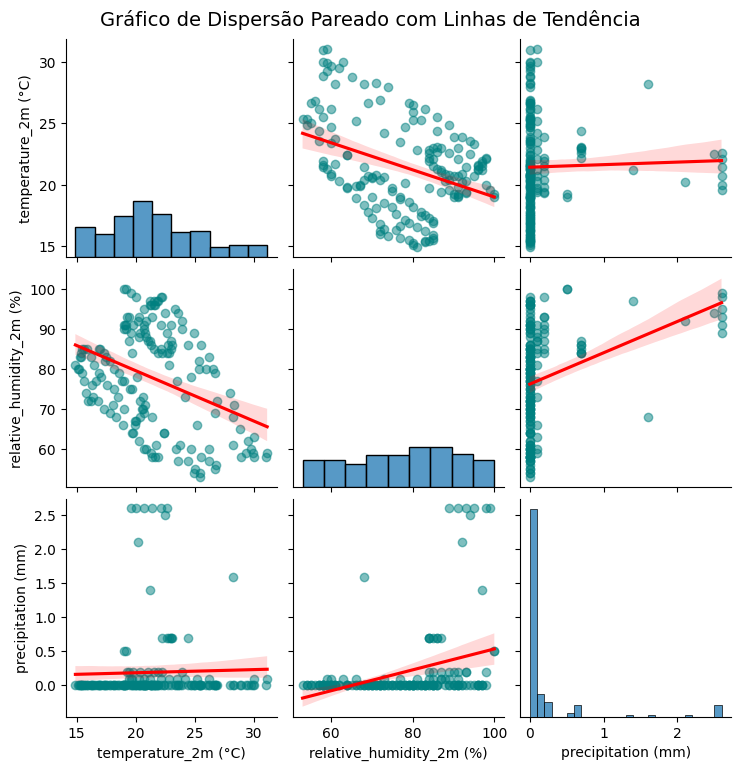

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# 1. Gráfico de dispersão pareado (Pairplot)
plt.figure(figsize=(10, 8))
sns.pairplot(df[['temperature_2m (°C)', 'relative_humidity_2m (%)', 'precipitation (mm)']],
             kind='reg',
             plot_kws={'line_kws':{'color':'red'}, 'scatter_kws': {'alpha': 0.5, 'color': 'teal'}})
plt.suptitle('Gráfico de Dispersão Pareado com Linhas de Tendência', y=1.02, fontsize=14)
plt.show()

#### **Interpretação dos Principais Resultados (Item a):**
- **Temperatura x Umidade:** O gráfico de dispersão e a reta vermelha de tendência confirmam que há uma tendência linear decrescente (negativa). À medida que a umidade do ar sobe, a temperatura média registrada cai.
- **Temperatura x Precipitação:** Os pontos de precipitação concentram-se fortemente próximos a zero (dias sem chuva). Quando ocorrem eventos de precipitação maiores, a temperatura tende a situar-se em faixas mais amenas, embora a distribuição seja bem dispersa.
- **Umidade x Precipitação:** Há uma clara concentração de dados em umidade elevada ($>80\%$) sempre que ocorrem registros de precipitação volumosa, o que indica que a umidade atua de forma correlacionada às chuvas.

### **b) Matriz de Covariância e Matriz de Correlação Linear de Pearson**

In [38]:
variaveis_multi = df[['temperature_2m (°C)', 'relative_humidity_2m (%)', 'precipitation (mm)']]

# calculos das matrizes
matriz_covarancia = variaveis_multi.cov()
matriz_correlacao = variaveis_multi.corr()

print("MATRIZ DE COVARIÂNCIA:")
display(matriz_covarancia)

print("\nMATRIZ DE CORRELAÇÃO DE PEARSON:")
display(matriz_correlacao)

MATRIZ DE COVARIÂNCIA:


,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm)
temperature_2m (°C),14.438853,-18.201832,0.066963
relative_humidity_2m (%),-18.201832,164.347163,2.525456
precipitation (mm),0.066963,2.525456,0.323113



MATRIZ DE CORRELAÇÃO DE PEARSON:


,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm)
temperature_2m (°C),1.000000,-0.373652,0.031002
relative_humidity_2m (%),-0.373652,1.000000,0.346562
precipitation (mm),0.031002,0.346562,1.000000


#### **Interpretação dos Resultados (Item b):**
- **Matriz de Covariância:**
  - A covariância entre Temperatura e Umidade é **$-18.2018$**. Por ser negativa, indica que as duas variáveis se movem em direções opostas de forma geral.
  - A covariância entre Temperatura e Precipitação é positiva mas baixa (**$0.0670$**).
  - A covariância entre Umidade e Precipitação é positiva (**$2.5255$**), confirmando o movimento associado de aumento mútuo.
- **Matriz de Correlação ($r$):**
  - **Temperatura x Umidade ($r = -0.3737$):** Correlação linear negativa moderada.
  - **Temperatura x Precipitação ($r = 0.0310$):** Correlação linear extremamente fraca (praticamente nula) de forma direta e isolada.
  - **Umidade x Precipitação ($r = 0.3466$):** Correlação linear positiva de intensidade moderada.

### **c) Gráfico de Correlação Linear de Pearson**

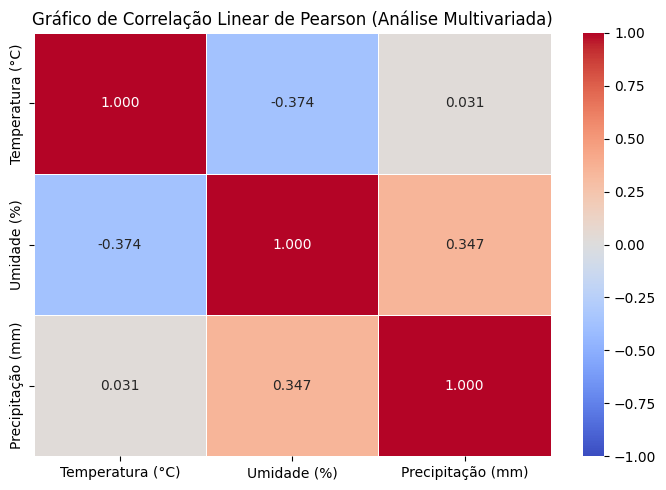

In [39]:
plt.figure(figsize=(7, 5))

matriz_corr_renomeada = matriz_correlacao.rename(
    columns={
        'temperature_2m (°C)': 'Temperatura (°C)',
        'relative_humidity_2m (%)': 'Umidade (%)',
        'precipitation (mm)': 'Precipitação (mm)'
    },
    index={
        'temperature_2m (°C)': 'Temperatura (°C)',
        'relative_humidity_2m (%)': 'Umidade (%)',
        'precipitation (mm)': 'Precipitação (mm)'
    }
)

sns.heatmap(matriz_corr_renomeada, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Gráfico de Correlação Linear de Pearson (Análise Multivariada)')
plt.tight_layout()
plt.show()

#### **Interpretação do Gráfico (Item c):**
O heatmap acima resume visualmente as correlações lineares. A escala de cores varia de $-1$ (azul, negativa) a $+1$ (vermelho, positiva). Fica nítido o tom azul suave entre Temperatura e Umidade indicando a relação inversa, e o tom de cinza entre Temperatura e Precipitação demonstrando ausência de relação linear direta isolada.

### **d) Equação da Regressão Linear Múltipla**

In [40]:
import statsmodels.api as sm

# saídas
X = df[['relative_humidity_2m (%)', 'precipitation (mm)']]
X_com_constante = sm.add_constant(X)
y = df['temperature_2m (°C)']

# um ajuste do modelo mltiplo pelo metodo dos Mínimos Quadrados Ordinários (OLS)
modelo_multiplo = sm.OLS(y, X_com_constante).fit()

# coeficientes
intercepto = modelo_multiplo.params['const']
coef_umidade = modelo_multiplo.params['relative_humidity_2m (%)']
coef_precip = modelo_multiplo.params['precipitation (mm)']

print("EQUAÇÃO DA REGRESSÃO LINEAR MÚLTIPLA:")
print(f"Temperatura Prevista = {intercepto:.4f} + ({coef_umidade:.4f}) * Umidade + ({coef_precip:.4f}) * Precipitação")

EQUAÇÃO DA REGRESSÃO LINEAR MÚLTIPLA:
Temperatura Prevista = 31.2847 + (-0.1295) * Umidade + (1.2193) * Precipitação


### **e) Verificação da Adequação do Modelo ($R^2$ e Teste F)**

In [41]:
r_quadrado = modelo_multiplo.rsquared
r_quadrado_ajustado = modelo_multiplo.rsquared_adj
f_calculado = modelo_multiplo.fvalue
p_valor_f = modelo_multiplo.f_pvalue

print(f"R² (Coeficiente de Determinação): {r_quadrado:.4f} ({r_quadrado * 100:.2f}%)")
print(f"R² Ajustado: {r_quadrado_ajustado:.4f} ({r_quadrado_ajustado * 100:.2f}%)")
print(f"Estatística F: {f_calculado:.4f}")
print(f"p-valor do Teste F: {p_valor_f:.4e}")

R² (Coeficiente de Determinação): 0.1689 (16.89%)
R² Ajustado: 0.1588 (15.88%)
Estatística F: 16.7650
p-valor do Teste F: 2.3539e-07


#### **Interpretação da Adequação (Item e):**
- **Coeficiente de Determinação ($R^2$):** O valor de **$0.1689$** mostra que **$16.89\%$** de toda a variação da temperatura medida na base de dados é explicada pela ação conjunta da umidade relativa do ar e da precipitação.
- **Significância Global (Teste F):** O p-valor associado à estatística F é de apenas **$2.35 \times 10^{-7}$**. Sendo absurdamente inferior ao nível de significância de $5\%$ ($0.05$), rejeitamos a hipótese nula ($H_0$) de que todos os coeficientes sejam nulos. Logo, concluímos que o modelo múltiplo é estatisticamente significativo e que a combinação das variáveis preditoras auxilia a prever a temperatura de forma robusta.

### **f) Previsão Utilizando Duas Variáveis Explicativas**

In [42]:
# Cenário: Umidade = 65% e Precipitação = 3.0 mm = Cenario Aleatorio que coloquei
umidade_cenario = 65.0
precip_cenario = 3.0

temp_prevista_multipla = intercepto + (coef_umidade * umidade_cenario) + (coef_precip * precip_cenario)

print("PREVISÃO MULTIVARIADA:")
print(f"Valores inseridos: Umidade = {umidade_cenario}% | Precipitação = {precip_cenario} mm")
print(f"Temperatura Prevista Estimada: {temp_prevista_multipla:.2f} °C")

PREVISÃO MULTIVARIADA:
Valores inseridos: Umidade = 65.0% | Precipitação = 3.0 mm
Temperatura Prevista Estimada: 26.53 °C


### **Exercício 6 - Análise Multivariada entre 03 variáveis quantitativas**

a) A Equação da Regressão Logística Binária.

b) A Matriz de Confusão e a Acurácia, interprete os resultados.

c) Uma classificação utilizando, pelo menos, 02 variáveis explicativas.

In [43]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# definido a variável resposta binária (Chuva: 1, Chuva Não: 0)
df['chuva'] = (df['precipitation (mm)'] > 0.1).astype(int)
y_log = df['chuva']

# definido as variáveis explicativas quantitativas
X_log = df[['temperature_2m (°C)', 'relative_humidity_2m (%)']]
X_log_const = sm.add_constant(X_log)

# treinando o modelo
modelo_logistico = sm.Logit(y_log, X_log_const).fit(disp=0)

### **a) Equação da Regressão Logística Binária**

In [44]:
intercepto_log = modelo_logistico.params['const']
coef_temp_log = modelo_logistico.params['temperature_2m (°C)']
coef_umid_log = modelo_logistico.params['relative_humidity_2m (%)']

print("EQUAÇÃO DO LOGIT (Z):")
print(f"Z = {intercepto_log:.4f} + ({coef_temp_log:.4f}) * Temperatura + ({coef_umid_log:.4f}) * Umidade\n")

print("EQUAÇÃO DA PROBABILIDADE P(Y=1):")
print("P(Chuva) = 1 / (1 + e^(-Z))")

EQUAÇÃO DO LOGIT (Z):
Z = -18.9812 + (0.2035) * Temperatura + (0.1552) * Umidade

EQUAÇÃO DA PROBABILIDADE P(Y=1):
P(Chuva) = 1 / (1 + e^(-Z))


### **b) Matriz de Confusão e Acurácia**

Acurácia Global do Modelo: 0.8095 (80.95%)



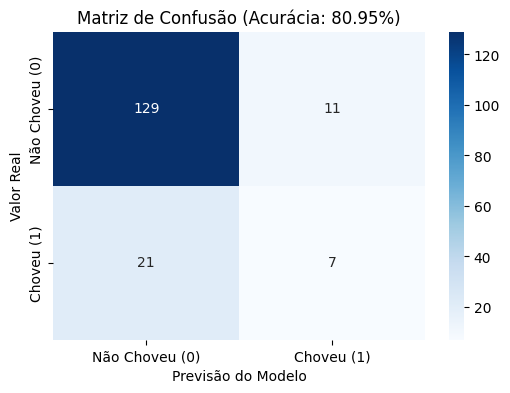

In [45]:
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# probabilidades previstas pelo modelo
prob_previstas = modelo_logistico.predict(X_log_const)

# classificacao utilizando ponto de corte de 0.5 (50%)
predicoes_binarias = (prob_previstas >= 0.5).astype(int)

# matriz de confusão e acurácia
matriz_conf = confusion_matrix(y_log, predicoes_binarias)
acuracia = accuracy_score(y_log, predicoes_binarias)

plt.figure(figsize=(6, 4))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Choveu (0)', 'Choveu (1)'],
            yticklabels=['Não Choveu (0)', 'Choveu (1)'])
plt.title(f'Matriz de Confusão (Acurácia: {acuracia * 100:.2f}%)')
plt.ylabel('Valor Real')
plt.xlabel('Previsão do Modelo')
print(f"Acurácia Global do Modelo: {acuracia:.4f} ({acuracia * 100:.2f}%)\n")
plt.show()

#### **Interpretação (Item b):**
O modelo apresenta uma taxa de acerto geral de 80.95%. Isso significa que, de cada 100 previsões feitas pelo modelo sobre se iria chover ou não baseado na temperatura e umidade, ele acertou aproximadamente 81 delas.

- O modelo previu corretamente que não choveria nos dois casos (129 casos) e, de fato, não choveu. Esse é o maior acerto do modelo.
- O modelo previu que não choveria, mas na realidade choveu (foram 21 casos). Esse acaba sendo um erro que representa um 'alarme falso negativo' (as pessoas seriam surpreendidas pela chuva sem aviso, no caso do nosso desafio, não avisado pelo assistente virtual).
- O modelo previu que choveria, mas não choveu (11 casos). É um erro do tipo 'alarme falso positivo'.
- O modelo previu corretamente que choveria e, de fato, choveu (foram 7 casos).

Essa pequena sensibilidade em detectar a chuva quando ela de fato ocorre seria porque a base de dados tem muito mais dias sem chuva do que dias chuvosos, gerando um conjunto desbalanceado.

### **c) Classificação utilizando 02 variáveis explicativas (Cenário de Exemplo)**

In [46]:
# cenário: Temperatura = 22 °C e Umidade = 95%
temp_teste = 22.0
umid_teste = 95.0

# calculo do Z
z_teste = intercepto_log + (coef_temp_log * temp_teste) + (coef_umid_log * umid_teste)

# calculo da probabilidade
prob_teste = 1 / (1 + np.exp(-z_teste))

# classificação
classificacao = "Chuva (1)" if prob_teste >= 0.5 else "Sem Chuva (0)"

print("CLASSIFICAÇÃO DO CENÁRIO:")
print(f"Valores: Temperatura = {temp_teste}°C | Umidade = {umid_teste}%")
print(f"Logit (Z): {z_teste:.4f}")
print(f"Probabilidade Estimada de Chuva: {prob_teste * 100:.2f}%")
print(f"Classificação Final: {classificacao}")

CLASSIFICAÇÃO DO CENÁRIO:
Valores: Temperatura = 22.0°C | Umidade = 95.0%
Logit (Z): 0.2399
Probabilidade Estimada de Chuva: 55.97%
Classificação Final: Chuva (1)
